In [10]:
import pandas as pd
from scipy.io import arff
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, precision_recall_curve

# A) 1. EDA JM1

In [12]:
# === CELL 1: EDA & PERSIAPAN LABEL ===
data, meta = arff.loadarff("JM1.arff")
df = pd.DataFrame(data)

print("Ukuran dataset:", df.shape)

print("\nDaftar kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())

print("\nTotal data kosong:", df.isna().sum().sum())
print("Total data duplikat:", df.duplicated().sum())

df["label"] = df["label"].apply(lambda x: 1 if x.decode("utf-8") == "Y" else 0)

print("\nDistribusi kelas (1=Cacat, 0=Normal):")
print(df["label"].value_counts())
print("\nTotal keseluruhan LOC:", int(df["LOC_TOTAL"].sum()))

Ukuran dataset: (7782, 22)

Daftar kolom:
['LOC_BLANK', 'BRANCH_COUNT', 'LOC_CODE_AND_COMMENT', 'LOC_COMMENTS', 'CYCLOMATIC_COMPLEXITY', 'DESIGN_COMPLEXITY', 'ESSENTIAL_COMPLEXITY', 'LOC_EXECUTABLE', 'HALSTEAD_CONTENT', 'HALSTEAD_DIFFICULTY', 'HALSTEAD_EFFORT', 'HALSTEAD_ERROR_EST', 'HALSTEAD_LENGTH', 'HALSTEAD_LEVEL', 'HALSTEAD_PROG_TIME', 'HALSTEAD_VOLUME', 'NUM_OPERANDS', 'NUM_OPERATORS', 'NUM_UNIQUE_OPERANDS', 'NUM_UNIQUE_OPERATORS', 'LOC_TOTAL', 'label']

5 data pertama:


,LOC_BLANK,BRANCH_COUNT,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CYCLOMATIC_COMPLEXITY,DESIGN_COMPLEXITY,ESSENTIAL_COMPLEXITY,LOC_EXECUTABLE,HALSTEAD_CONTENT,HALSTEAD_DIFFICULTY,...,HALSTEAD_LENGTH,HALSTEAD_LEVEL,HALSTEAD_PROG_TIME,HALSTEAD_VOLUME,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,LOC_TOTAL,label
0,1.0,7.0,0.0,0.0,4.0,3.0,1.0,11.0,25.05,11.20,...,59.0,0.09,174.56,280.54,28.0,31.0,15.0,12.0,14.0,b'N'
1,5.0,37.0,0.0,6.0,19.0,16.0,10.0,85.0,81.19,27.41,...,351.0,0.04,3388.22,2225.29,147.0,204.0,59.0,22.0,98.0,b'N'
2,2.0,1.0,0.0,0.0,1.0,1.0,1.0,10.0,56.44,2.83,...,37.0,0.35,25.17,159.91,17.0,20.0,15.0,5.0,14.0,b'Y'
3,16.0,1.0,0.0,0.0,1.0,1.0,1.0,52.0,168.57,16.97,...,450.0,0.06,2697.42,2860.90,198.0,252.0,70.0,12.0,70.0,b'Y'
4,0.0,7.0,0.0,0.0,4.0,2.0,3.0,9.0,14.32,7.71,...,26.0,0.13,47.33,110.45,9.0,17.0,7.0,12.0,12.0,b'N'



Total data kosong: 0
Total data duplikat: 0

Distribusi kelas (1=Cacat, 0=Normal):
label
0    6110
1    1672
Name: count, dtype: int64

Total keseluruhan LOC: 359924


# A) 2. Preprocessing JM1

In [13]:
# 1. Pisahkan fitur (X) dan target (y)
X = df.drop(columns=["label"])
y = df["label"]

# 2. Bagi data: 20% Test, 80% sisanya (X_temp)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Bagi 80% tadi menjadi Train (60% total) dan Validation (20% total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

# 3. Simpan kolom LOC_TOTAL asli sebelum di-scaling (untuk menghitung anggaran inspeksi 20% LOC)
loc_val = X_val["LOC_TOTAL"].values
loc_test = X_test["LOC_TOTAL"].values

# 4. Scaling fitur (fit HANYA pada data Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Pembagian selesai -> Train: 4668 | Validation: 1557 | Test: 1557


# A) 3. Fungsi Evaluasi Cost Aware


In [14]:
def evaluasi_model(model, X_data, y_data, loc_data):
    y_pred = model.predict(X_data)                 # Prediksi kelas biner (0 atau 1)
    y_prob = model.predict_proba(X_data)[:, 1]     # Skor probabilitas cacat

    # Metrik klasifikasi standar
    pr_auc = average_precision_score(y_data, y_prob)
    prec = precision_score(y_data, y_pred)
    rec = recall_score(y_data, y_pred)

    # Skenario B: Urutkan modul dari probabilitas cacat tertinggi ke terendah
    tabel_rank = pd.DataFrame({
        "y_true": y_data.values,
        "y_prob": y_prob,
        "loc": loc_data
    }).sort_values(by="y_prob", ascending=False).reset_index(drop=True)

    # Skenario C: Ambil modul teratas sampai kumulatif LOC <= 20% dari total LOC
    tabel_rank["cum_loc"] = tabel_rank["loc"].cumsum()
    batas_loc_20 = 0.20 * tabel_rank["loc"].sum()
    modul_diinspeksi = tabel_rank[tabel_rank["cum_loc"] <= batas_loc_20]

    cacat_ditemukan = int(modul_diinspeksi["y_true"].sum())
    total_cacat = int(tabel_rank["y_true"].sum())
    recall_20_loc = cacat_ditemukan / total_cacat

    return pr_auc, prec, rec, recall_20_loc, cacat_ditemukan, total_cacat, tabel_rank

# Hitung juga pembanding Strategi Acak (Random) di Test Set untuk menguji Hipotesis H1
rng = np.random.default_rng(42)
skor_acak = []
for _ in range(100):
    idx_acak = rng.permutation(len(y_test))
    df_acak = pd.DataFrame({"y_true": y_test.values[idx_acak], "loc": loc_test[idx_acak]})
    df_acak["cum_loc"] = df_acak["loc"].cumsum()
    terpilih = df_acak[df_acak["cum_loc"] <= 0.20 * df_acak["loc"].sum()]
    skor_acak.append(terpilih["y_true"].sum() / df_acak["y_true"].sum())

print(f"Rata-rata Recall@20%LOC Strategi Acak (Test): {np.mean(skor_acak):.4f}")

Rata-rata Recall@20%LOC Strategi Acak (Test): 0.2004


# A) 4. Training dan Evaluasi Model

In [15]:
daftar_model = {
    "Baseline - Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Baseline - Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Skenario A - LR (Class Weight)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Skenario A - RF (Class Weight)": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
}

hasil_list = []
kurva_data = {}

for nama, model in daftar_model.items():
    model.fit(X_train_scaled, y_train)

    # Evaluasi pada Validation dan Test
    val_pr, _, _, val_r20, _, _, _ = evaluasi_model(model, X_val_scaled, y_val, loc_val)
    test_pr, test_p, test_r, test_r20, found, tot, tabel_rank = evaluasi_model(model, X_test_scaled, y_test, loc_test)

    hasil_list.append({
        "Model / Skenario": nama,
        "Val PR-AUC": round(val_pr, 4),
        "Val Recall@20%LOC": round(val_r20, 4),
        "Test PR-AUC": round(test_pr, 4),
        "Test Precision": round(test_p, 4),
        "Test Recall": round(test_r, 4),
        "Test Recall@20%LOC": round(test_r20, 4),
        "Defects Found (Test)": f"{found}/{tot}"
    })
    kurva_data[nama] = (tabel_rank, y_test.values, model.predict_proba(X_test_scaled)[:, 1])

hasil_df = pd.DataFrame(hasil_list)
display(hasil_df)
hasil_df.to_csv("metrics.csv", index=False)

,Model / Skenario,Val PR-AUC,Val Recall@20%LOC,Test PR-AUC,Test Precision,Test Recall,Test Recall@20%LOC,Defects Found (Test)
0,Baseline - Logistic Regression,0.3854,0.1228,0.3607,0.4706,0.0955,0.0776,26/335
1,Baseline - Random Forest,0.4038,0.1796,0.3549,0.4186,0.1612,0.1134,38/335
2,Skenario A - LR (Class Weight),0.3877,0.1168,0.3601,0.3272,0.4746,0.0776,26/335
3,Skenario A - RF (Class Weight),0.4008,0.1677,0.3649,0.4365,0.1642,0.1254,42/335


# A) 5. Visualisasi Grafik

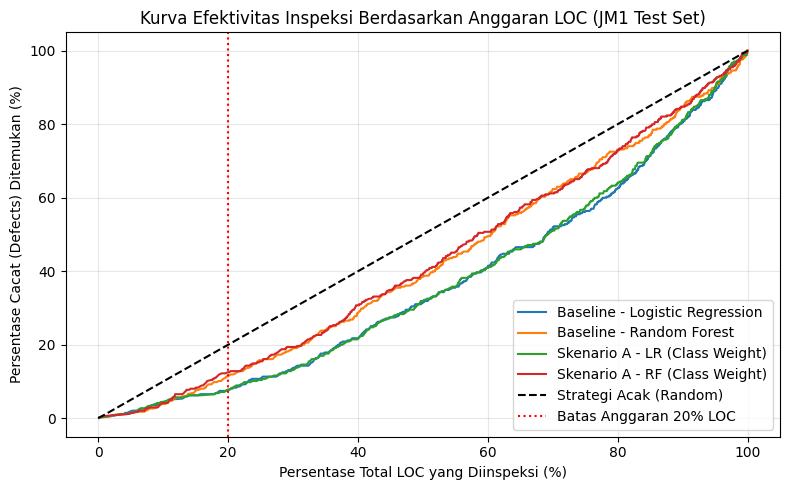

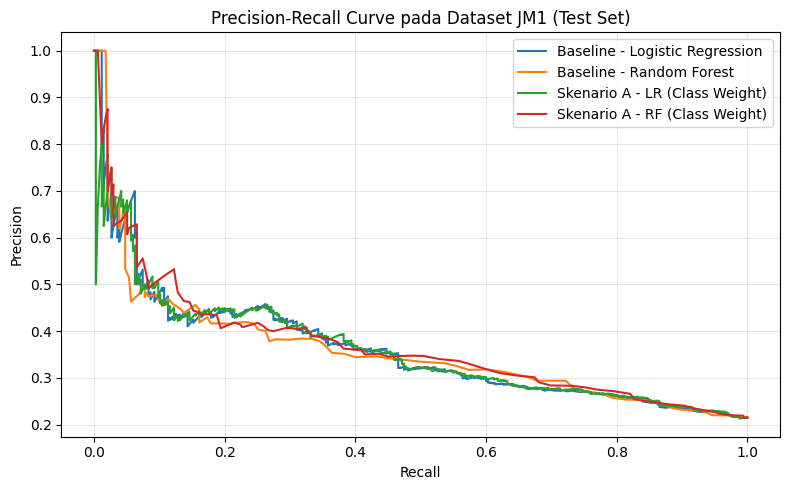

In [16]:
# Grafik 1: Effort Aware Curve (% LOC diinspeksi vs % Cacat ditemukan)
plt.figure(figsize=(8, 5))
for nama, (tabel_rank, _, _) in kurva_data.items():
    persen_loc = (tabel_rank["cum_loc"] / tabel_rank["loc"].sum()) * 100
    persen_cacat = (tabel_rank["y_true"].cumsum() / tabel_rank["y_true"].sum()) * 100
    plt.plot(persen_loc, persen_cacat, label=nama)

plt.plot([0, 100], [0, 100], "k--", label="Strategi Acak (Random)")
plt.axvline(x=20, color="red", linestyle=":", label="Batas Anggaran 20% LOC")
plt.xlabel("Persentase Total LOC yang Diinspeksi (%)")
plt.ylabel("Persentase Cacat (Defects) Ditemukan (%)")
plt.title("Kurva Efektivitas Inspeksi Berdasarkan Anggaran LOC (JM1 Test Set)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("kurva_budget_loc.png", dpi=300)
plt.show()

# Grafik 2: Precision Recall Curve
plt.figure(figsize=(8, 5))
for nama, (_, y_true_arr, y_prob_arr) in kurva_data.items():
    p_curve, r_curve, _ = precision_recall_curve(y_true_arr, y_prob_arr)
    plt.plot(r_curve, p_curve, label=nama)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve pada Dataset JM1 (Test Set)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("kurva_pr.png", dpi=300)
plt.show()